In [4]:
from google.colab import drive

drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
zip_path = "/content/drive/MyDrive/ycbv_pbr_subset.zip"

import os
import zipfile

extract_dir = "/content/drive/MyDrive/ycbv_pbr_subset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extraction complete.")
print("Top-level contents:", os.listdir(extract_dir))

Extraction complete.
Top-level contents: ['ycbv_pbr_subset']


In [6]:
import os

dataset_root = "/content/drive/MyDrive/ycbv_pbr_subset/ycbv_pbr_subset/train_pbr"

for scene_id in ["000000", "000001", "000002", "000003"]:
    scene_path = os.path.join(dataset_root, scene_id)

    print(
        scene_id,
        "RGB images:", len(os.listdir(os.path.join(scene_path, "rgb"))),
        "Files:", os.listdir(scene_path)
    )

000000 RGB images: 100 Files: ['scene_camera.json', 'scene_gt.json', 'scene_gt_info.json', 'rgb']
000001 RGB images: 100 Files: ['scene_camera.json', 'scene_gt.json', 'scene_gt_info.json', 'rgb']
000002 RGB images: 100 Files: ['scene_camera.json', 'scene_gt.json', 'scene_gt_info.json', 'rgb']
000003 RGB images: 100 Files: ['scene_camera.json', 'scene_gt.json', 'scene_gt_info.json', 'rgb']


In [7]:
object_names = {
    1: "Master Chef Can",
    2: "Cracker Box",
    3: "Sugar Box",
    4: "Tomato Soup Can",
    5: "Mustard Bottle",
    6: "Tuna Fish Can",
    7: "Pudding Box",
    8: "Gelatin Box",
    9: "Potted Meat Can",
    10: "Banana",
    11: "Pitcher Base",
    12: "Bleach Cleanser",
    13: "Bowl",
    14: "Mug",
    15: "Power Drill",
    16: "Wood Block",
    17: "Scissors",
    18: "Large Marker",
    19: "Large Clamp",
    20: "Extra Large Clamp",
    21: "Foam Brick"
}
def get_object_name(obj_id):
    return object_names.get(obj_id, f"Object {obj_id}")

In [8]:
# Inspect how the annotations correspond to objects

import os
import json
from collections import Counter

scene_id = "000000"
scene_path = os.path.join(dataset_root, scene_id)

with open(os.path.join(scene_path, "scene_gt.json")) as f:
    scene_gt = json.load(f)

with open(os.path.join(scene_path, "scene_gt_info.json")) as f:
    scene_gt_info = json.load(f)

# Select the first available image
image_id = sorted(scene_gt.keys(), key=int)[0]

objects = scene_gt[image_id]
object_info = scene_gt_info[image_id]

print("Image ID:", image_id)
print("Number of object instances:", len(objects))
print("Number of annotation records:", len(object_info))
print()

for i, (obj, info) in enumerate(zip(objects, object_info)):
    obj_id = obj["obj_id"]

    print(f"Instance {i + 1}")
    print("  Object ID:", obj_id)
    print("  Object name:", object_names[obj_id])
    print("  Full bounding box:", info["bbox_obj"])
    print("  Visible bounding box:", info["bbox_visib"])
    print("  Visible fraction:", info["visib_fract"])
    print()

Image ID: 3
Number of object instances: 21
Number of annotation records: 21

Instance 1
  Object ID: 1
  Object name: Master Chef Can
  Full bounding box: [233, 227, 187, 190]
  Visible bounding box: [233, 227, 183, 177]
  Visible fraction: 0.8984439406430338

Instance 2
  Object ID: 20
  Object name: Extra Large Clamp
  Full bounding box: [180, 337, 232, 186]
  Visible bounding box: [183, 337, 229, 142]
  Visible fraction: 0.6975475130151163

Instance 3
  Object ID: 5
  Object name: Mustard Bottle
  Full bounding box: [417, 239, 146, 245]
  Visible bounding box: [417, 239, 146, 240]
  Visible fraction: 0.8992826517150396

Instance 4
  Object ID: 11
  Object name: Pitcher Base
  Full bounding box: [505, 30, 314, 290]
  Visible bounding box: [505, 30, 134, 226]
  Visible fraction: 0.37621182511399776

Instance 5
  Object ID: 4
  Object name: Tomato Soup Can
  Full bounding box: [259, 180, 104, 118]
  Visible bounding box: [290, 216, 53, 58]
  Visible fraction: 0.06600153491941672

Insta

In [9]:
# Measure training data before extracting crops
from collections import defaultdict

scenes = {
    "train": ["000000", "000001", "000002"],
    "validation": ["000003"]
}

object_counts = {
    split: defaultdict(lambda: {
        "total": 0,
        "invisible": 0,
        "low_visibility": 0,
        "usable": 0
    })
    for split in scenes
}

for split, scene_ids in scenes.items():

    for scene_id in scene_ids:

        scene_path = os.path.join(dataset_root, scene_id)

        with open(os.path.join(scene_path, "scene_gt.json")) as f:
            ground_truth = json.load(f)

        with open(os.path.join(scene_path, "scene_gt_info.json")) as f:
            gt_info = json.load(f)

        for image_id, annotations in ground_truth.items():

            info_records = gt_info[image_id]

            for annotation, info in zip(annotations, info_records):

                obj_id = annotation["obj_id"]
                bbox = info["bbox_obj"]
                visibility = info["visib_fract"]

                counts = object_counts[split][obj_id]
                counts["total"] += 1

                if bbox == [-1, -1, -1, -1] or visibility == 0:
                    counts["invisible"] += 1

                elif visibility < 0.20:
                    counts["low_visibility"] += 1

                else:
                    counts["usable"] += 1

for split in scenes:

    print(f"\n")
    print(f"{split.upper()} DATA")

    print(
        f"{'Object ID':<12}"
        f"{'Total':<10}"
        f"{'Invisible':<12}"
        f"{'Low vis.':<12}"
        f"{'Usable':<10}"
    )

    for obj_id in range(1, 22):

        c = object_counts[split][obj_id]

        print(
            f"{obj_id:<12}"
            f"{c['total']:<10}"
            f"{c['invisible']:<12}"
            f"{c['low_visibility']:<12}"
            f"{c['usable']:<10}"
        )



TRAIN DATA
Object ID   Total     Invisible   Low vis.    Usable    
1           300       79          52          169       
2           300       53          52          195       
3           300       74          66          160       
4           300       81          47          172       
5           299       56          60          183       
6           300       101         44          155       
7           300       76          45          179       
8           300       89          60          151       
9           300       108         51          141       
10          294       84          64          146       
11          295       70          56          169       
12          296       67          57          172       
13          297       74          55          168       
14          300       96          44          160       
15          300       63          53          184       
16          300       69          57          174       
17          296   

In [10]:
# Prepare object crops

TRAIN_SCENES = ["000000", "000001", "000002"]
VAL_SCENES = ["000003"]

MARGIN = 0.35
TRAIN_MIN_VISIBILITY = 0.20

def build_crop_records(scene_ids, split):

    records = []

    for scene_id in scene_ids:

        scene_path = os.path.join(dataset_root, scene_id)

        with open(os.path.join(scene_path, "scene_gt.json")) as f:
            ground_truth = json.load(f)

        with open(os.path.join(scene_path, "scene_gt_info.json")) as f:
            gt_info = json.load(f)

        for image_id, annotations in ground_truth.items():

            info_records = gt_info[image_id]

            image_path = os.path.join(
                scene_path,
                "rgb",
                f"{int(image_id):06d}.jpg"
            )

            for instance_idx, (annotation, info) in enumerate(
                zip(annotations, info_records)
            ):

                obj_id = annotation["obj_id"]
                visibility = info["visib_fract"]
                bbox = info["bbox_obj"]

                # Exclude objects that have no valid projected bounding box.
                if bbox == [-1, -1, -1, -1]:
                    continue

                # Exclude completely invisible objects.
                if visibility <= 0:
                    continue

                # Apply the training visibility threshold only to training.
                if split == "train" and visibility < TRAIN_MIN_VISIBILITY:
                    continue

                records.append({
                    "scene_id": scene_id,
                    "image_id": image_id,
                    "instance_idx": instance_idx,
                    "obj_id": obj_id,
                    "visibility": visibility,
                    "bbox_obj": bbox,
                    "image_path": image_path
                })

    return records


train_records = build_crop_records(TRAIN_SCENES, "train")
val_records = build_crop_records(VAL_SCENES, "validation")

print("Training records:", len(train_records))
print("Validation records:", len(val_records))

Training records: 3416
Validation records: 1534


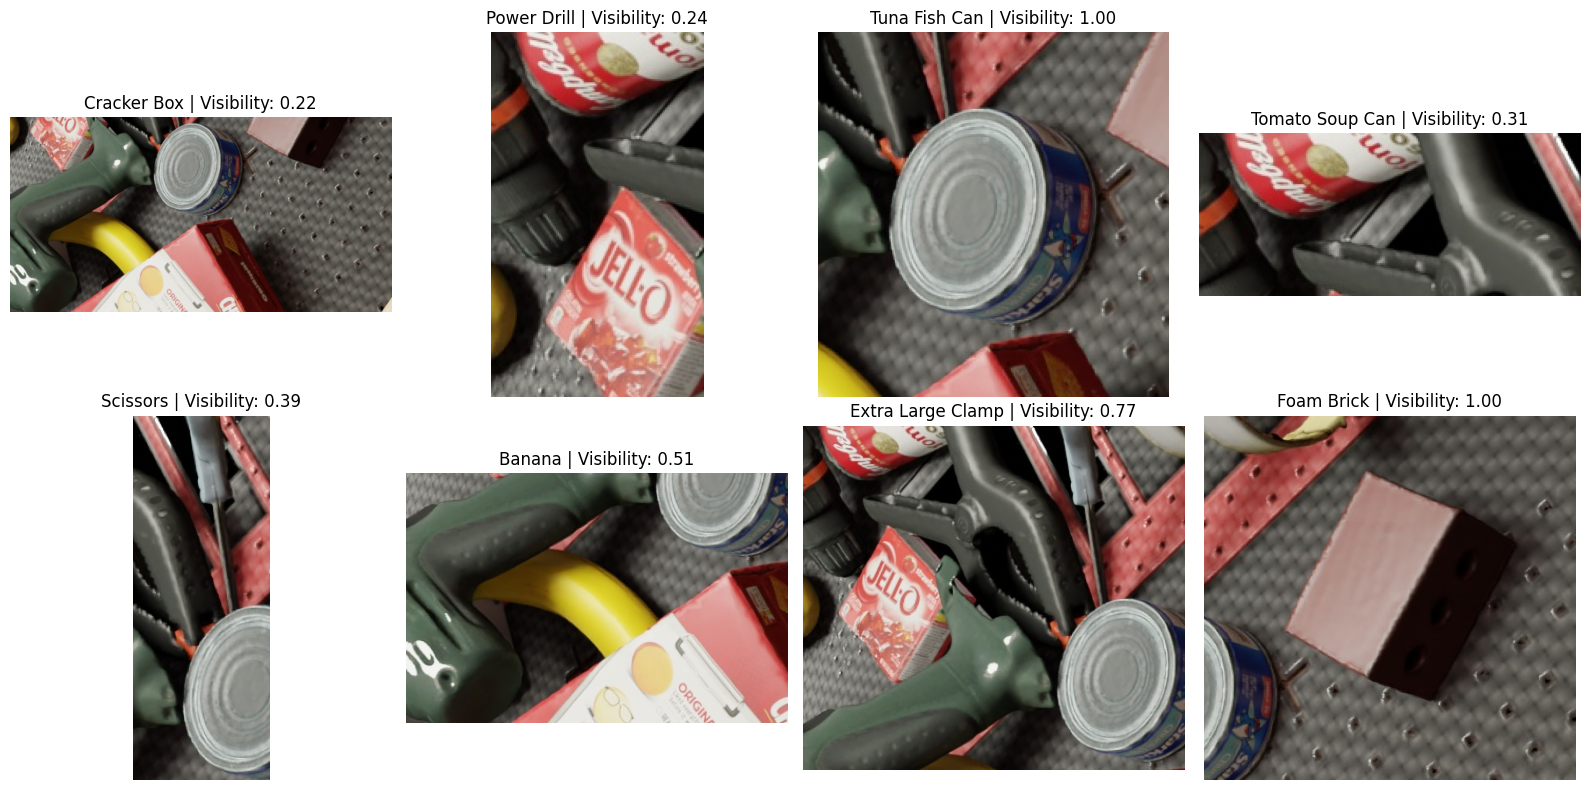

In [11]:
# Inspect a few crops

import matplotlib.pyplot as plt
from PIL import Image

def extract_crop(record, margin=0.35):

    image = Image.open(record["image_path"]).convert("RGB")

    x, y, w, h = record["bbox_obj"]

    # Expand the full object bounding box.
    x1 = int(x - margin * w)
    y1 = int(y - margin * h)
    x2 = int(x + w + margin * w)
    y2 = int(y + h + margin * h)

    # Clip coordinates to image boundaries.
    image_width, image_height = image.size

    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(image_width, x2)
    y2 = min(image_height, y2)

    return image.crop((x1, y1, x2, y2))


# Inspect examples from the training records.
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, record in zip(axes.flat, train_records[:8]):

    crop = extract_crop(record)

    ax.imshow(crop)
    ax.set_title(
        f"{get_object_name(record['obj_id'])} | "
        f"Visibility: {record['visibility']:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
from collections import Counter
import numpy as np

print("Training crops:", len(train_records))
print("Validation crops:", len(val_records))

train_class_counts = Counter(
    record["obj_id"] for record in train_records
)

val_class_counts = Counter(
    record["obj_id"] for record in val_records
)

print("\nTraining examples per class:")
for obj_id in range(1, 22):
    print(f"Object {obj_id:2d}: {train_class_counts[obj_id]}")

print("\nValidation examples per class:")
for obj_id in range(1, 22):
    print(f"Object {obj_id:2d}: {val_class_counts[obj_id]}")

# Inspect crop dimensions
crop_dimensions = []

for record in train_records:
    crop = extract_crop(record)
    crop_dimensions.append(crop.size)

widths = [w for w, h in crop_dimensions]
heights = [h for w, h in crop_dimensions]

print("\nCrop dimension statistics:")
print("Minimum width:", min(widths))
print("Maximum width:", max(widths))
print("Minimum height:", min(heights))
print("Maximum height:", max(heights))
print("Average width:", round(np.mean(widths), 2))
print("Average height:", round(np.mean(heights), 2))

Training crops: 3416
Validation crops: 1534

Training examples per class:
Object  1: 169
Object  2: 195
Object  3: 160
Object  4: 172
Object  5: 183
Object  6: 155
Object  7: 179
Object  8: 151
Object  9: 141
Object 10: 146
Object 11: 169
Object 12: 172
Object 13: 168
Object 14: 160
Object 15: 184
Object 16: 174
Object 17: 135
Object 18: 112
Object 19: 155
Object 20: 174
Object 21: 162

Validation examples per class:
Object  1: 83
Object  2: 78
Object  3: 79
Object  4: 64
Object  5: 69
Object  6: 65
Object  7: 77
Object  8: 66
Object  9: 74
Object 10: 73
Object 11: 78
Object 12: 77
Object 13: 80
Object 14: 80
Object 15: 74
Object 16: 76
Object 17: 72
Object 18: 66
Object 19: 61
Object 20: 72
Object 21: 70

Crop dimension statistics:
Minimum width: 42
Maximum width: 640
Minimum height: 31
Maximum height: 480
Average width: 259.07
Average height: 235.92


In [13]:
# Download the Dinov2 model
import torch

model = torch.hub.load(
    'facebookresearch/dinov2',
    'dinov2_vits14'
)

model.eval()

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 225MB/s]


DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-11): 12 x NestedTensorBlock(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (norm): LayerNorm((384,), eps=1

In [14]:
# DINOv2 input settings
IMAGE_SIZE = 518

# ImageNet channel statistics used for normalization
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def preprocess_dinov2(image, image_size=IMAGE_SIZE):

    # Ensure the image has three RGB channels
    image = image.convert("RGB")

    # Get the original width and height
    width, height = image.size

    # Find the size of the square canvas
    square_size = max(width, height)

    # Create a square canvas.
    # Its colour is set to the ImageNet mean so that the padding becomes approximately zero after normalization.
    mean_colour = tuple(
        round(value * 255) for value in IMAGENET_MEAN
    )

    square_image = Image.new(
        "RGB",
        (square_size, square_size),
        mean_colour
    )

    # Calculate where to place the original image
    left = (square_size - width) // 2
    top = (square_size - height) // 2

    # Place the original image in the centre so no stretching or distortion occurs here.
    square_image.paste(image, (left, top))

    # Resize the square image to 518 x 518
    resized_image = square_image.resize(
        (image_size, image_size),
        Image.Resampling.BICUBIC
    )

    # Convert image pixels into a NumPy array
    image_array = np.array(resized_image).astype(np.float32)

    # Scale pixel values from [0, 255] to [0, 1]
    image_array = image_array / 255.0

    # Convert from H x W x C to C x H x W
    image_tensor = torch.from_numpy(
        image_array
    ).permute(2, 0, 1)

    # Normalize each RGB channel
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    image_tensor = (image_tensor - mean) / std

    return resized_image, image_tensor

In [15]:
# Extract features

import torch
import numpy as np
from tqdm.auto import tqdm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

BATCH_SIZE = 16 if device.type == "cuda" else 4


def extract_dinov2_features(records, batch_size=BATCH_SIZE):

    all_features = []
    all_labels = []
    all_visibility = []

    for start in tqdm(range(0, len(records), batch_size)):

        batch_records = records[start:start + batch_size]

        batch_tensors = []

        for record in batch_records:

            crop = extract_crop(record)

            _, tensor = preprocess_dinov2(crop)

            batch_tensors.append(tensor)

        batch = torch.stack(batch_tensors).to(device)

        with torch.inference_mode():

            output = model.forward_features(batch)

            features = output["x_norm_clstoken"]

        all_features.append(features.cpu().numpy())

        all_labels.extend([
            record["obj_id"] - 1
            for record in batch_records
        ])

        all_visibility.extend([
            record["visibility"]
            for record in batch_records
        ])

    return (
        np.concatenate(all_features),
        np.array(all_labels),
        np.array(all_visibility)
    )


print("Extracting training features...")

X_train, y_train, train_visibility = extract_dinov2_features(
    train_records
)

print("\nExtracting validation features...")

X_val, y_val, val_visibility = extract_dinov2_features(
    val_records
)

Extracting training features...


  0%|          | 0/854 [00:00<?, ?it/s]


Extracting validation features...


  0%|          | 0/384 [00:00<?, ?it/s]

In [16]:
# Verify results

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)

print("Validation features:", X_val.shape)
print("Validation labels:", y_val.shape)

print("\nFeature data type:", X_train.dtype)
print("NaN values:", np.isnan(X_train).sum())
print("Infinite values:", np.isinf(X_train).sum())

print("\nTraining classes:", len(np.unique(y_train)))
print("Validation classes:", len(np.unique(y_val)))

Training features: (3416, 384)
Training labels: (3416,)
Validation features: (1534, 384)
Validation labels: (1534,)

Feature data type: float32
NaN values: 0
Infinite values: 0

Training classes: 21
Validation classes: 21


In [17]:
# Train the classifier

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Build the classifier.
classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )
)

# Train using the training features.
classifier.fit(X_train, y_train)

print("Classifier training complete.")

Classifier training complete.


In [18]:
# Evaluate on validation dataset

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate predictions.
y_pred = classifier.predict(X_val)

# Calculate evaluation metrics.
accuracy = accuracy_score(y_val, y_pred)

balanced_acc = balanced_accuracy_score(
    y_val, y_pred
)

macro_f1 = f1_score(
    y_val, y_pred, average="macro"
)

print("VALIDATION RESULTS")
print("\n")

print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced accuracy: {balanced_acc:.4f}")
print(f"Macro F1-score:    {macro_f1:.4f}")

print("\nPER-CLASS CLASSIFICATION REPORT")
print("\n")

print(
    classification_report(
        y_val,
        y_pred,
        labels=list(range(21)),
        target_names=[
            "Master Chef Can",
            "Cracker Box",
            "Sugar Box",
            "Tomato Soup Can",
            "Mustard Bottle",
            "Tuna Fish Can",
            "Pudding Box",
            "Gelatin Box",
            "Potted Meat Can",
            "Banana",
            "Pitcher Base",
            "Bleach Cleanser",
            "Bowl",
            "Mug",
            "Power Drill",
            "Wood Block",
            "Scissors",
            "Large Marker",
            "Large Clamp",
            "Extra Large Clamp",
            "Foam Brick"
        ],
        zero_division=0
    )
)

VALIDATION RESULTS


Accuracy:          0.3742
Balanced accuracy: 0.3720
Macro F1-score:    0.3710

PER-CLASS CLASSIFICATION REPORT


                   precision    recall  f1-score   support

  Master Chef Can       0.33      0.40      0.36        83
      Cracker Box       0.44      0.42      0.43        78
        Sugar Box       0.24      0.30      0.27        79
  Tomato Soup Can       0.43      0.39      0.41        64
   Mustard Bottle       0.29      0.33      0.31        69
    Tuna Fish Can       0.47      0.52      0.50        65
      Pudding Box       0.24      0.25      0.24        77
      Gelatin Box       0.23      0.23      0.23        66
  Potted Meat Can       0.42      0.34      0.37        74
           Banana       0.39      0.53      0.45        73
     Pitcher Base       0.43      0.49      0.46        78
  Bleach Cleanser       0.42      0.34      0.37        77
             Bowl       0.45      0.41      0.43        80
              Mug       0.50      0.44 

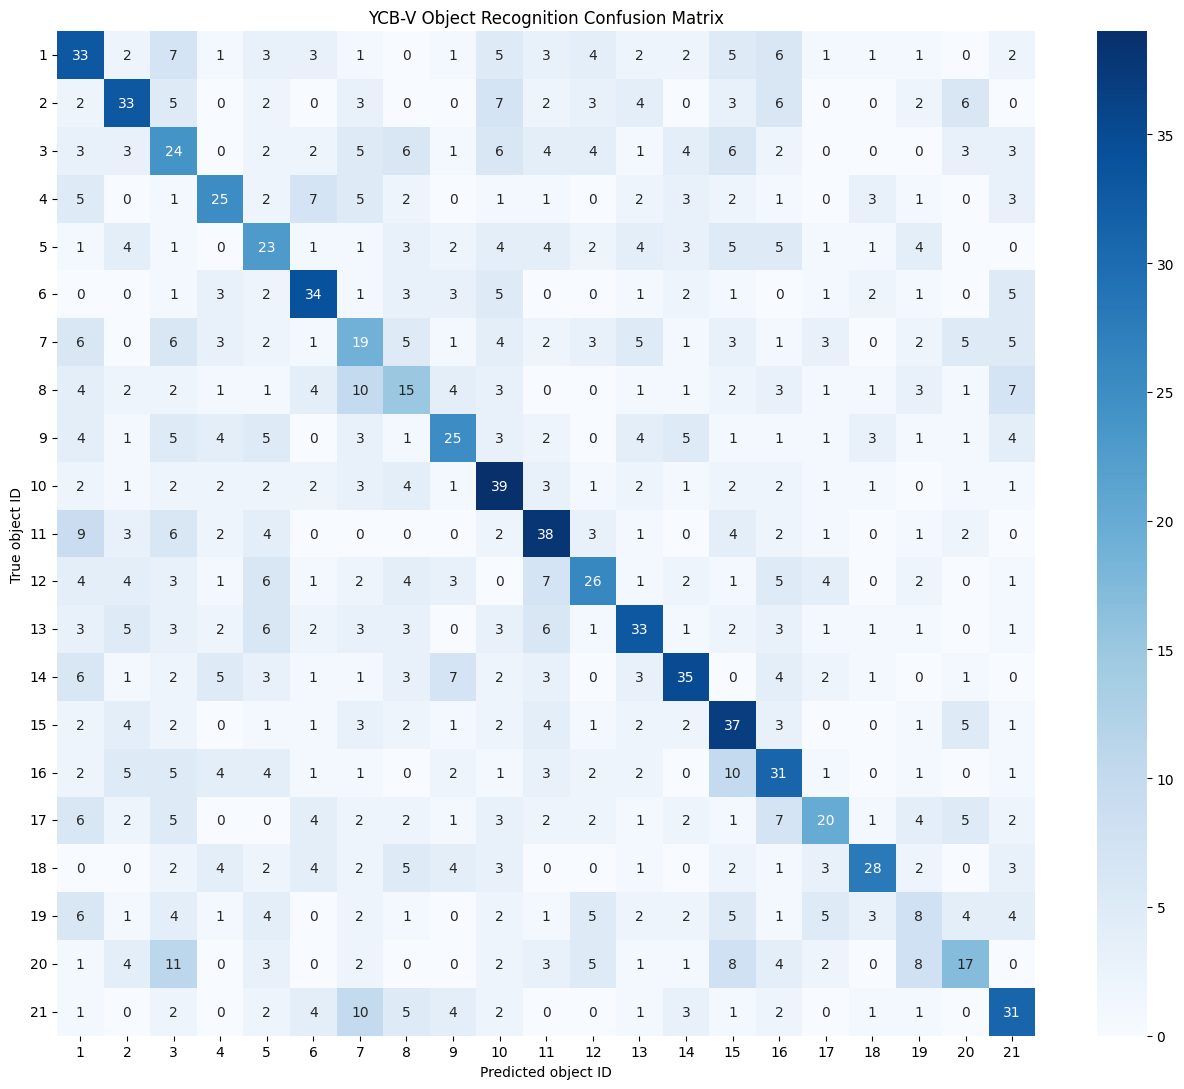

In [19]:
# Plot confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=list(range(21))
)

plt.figure(figsize=(13, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted object ID")
plt.ylabel("True object ID")
plt.title("YCB-V Object Recognition Confusion Matrix")

plt.xticks(
    ticks=np.arange(21) + 0.5,
    labels=np.arange(1, 22)
)

plt.yticks(
    ticks=np.arange(21) + 0.5,
    labels=np.arange(1, 22),
    rotation=0
)

plt.tight_layout()
plt.show()

In [22]:
# Inspect accuracy based on visibility level

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Predicted labels are already available as y_pred.
# Ground-truth labels are y_val.
# Visibility values are stored in val_visibility.

visibility_bins = [
    (0.0, 0.2),
    (0.2, 0.4),
    (0.4, 0.6),
    (0.6, 0.8),
    (0.8, 1.000001)
]

results = []

for lower, upper in visibility_bins:

    mask = (
        (val_visibility >= lower) &
        (val_visibility < upper)
    )

    y_true_bin = y_val[mask]
    y_pred_bin = y_pred[mask]

    if len(y_true_bin) == 0:
        continue

    results.append({
        "Visibility range": f"{lower:.0%}–{min(upper, 1.0):.0%}",
        "Samples": len(y_true_bin),
        "Accuracy": accuracy_score(
            y_true_bin, y_pred_bin
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_true_bin, y_pred_bin
        ),
        "Macro F1": f1_score(
            y_true_bin,
            y_pred_bin,
            average="macro",
            zero_division=0
        )
    })

visibility_results = pd.DataFrame(results)

print(visibility_results.to_string(index=False))

Visibility range  Samples  Accuracy  Balanced accuracy  Macro F1
          0%–20%      407  0.090909           0.089667  0.084839
         20%–40%      256  0.250000           0.244887  0.244551
         40%–60%      221  0.361991           0.361537  0.358873
         60%–80%      236  0.487288           0.493168  0.488079
        80%–100%      414  0.671498           0.657477  0.656832


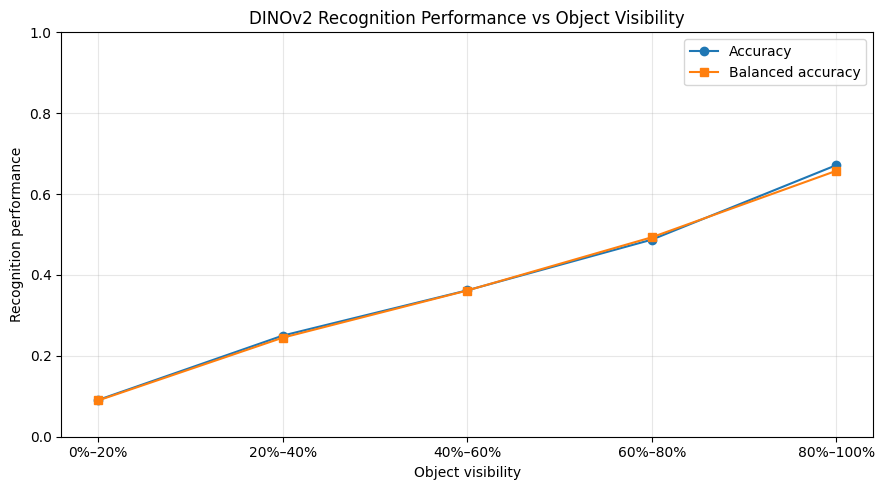

In [23]:
# Plot results

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    visibility_results["Visibility range"],
    visibility_results["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    visibility_results["Visibility range"],
    visibility_results["Balanced accuracy"],
    marker="s",
    label="Balanced accuracy"
)

plt.xlabel("Object visibility")
plt.ylabel("Recognition performance")
plt.title("DINOv2 Recognition Performance vs Object Visibility")

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
# Download the YCB-V Dataset

import os

os.makedirs("/content/ycbv", exist_ok=True)

%cd /content/ycbv

# Dataset metadata
!wget -c https://huggingface.co/datasets/bop-benchmark/ycbv/resolve/main/ycbv_base.zip

# Selected test images
!wget -c https://huggingface.co/datasets/bop-benchmark/ycbv/resolve/main/ycbv_test_bop19.zip

/content/ycbv
--2026-11-13 18:25:55--  https://huggingface.co/datasets/bop-benchmark/ycbv/resolve/main/ycbv_base.zip
Resolving huggingface.co (huggingface.co)... 13.35.202.121, 13.35.202.34, 13.35.202.97, ...
Connecting to huggingface.co (huggingface.co)|13.35.202.121|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/679cbae3b7477d5bd98d2c7b/7da0c2d50e020426eb793d83272d210153cc1c1e8af99bd538ed794e721c4e53?response-content-type=application%2Fzip&user_id=public&xip=scPc9B33JSs&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27ycbv_base.zip%3B+filename%3D%22ycbv_base.zip%22%3B&X-Xet-Cas-Uid=public&Expires=1794597955&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjc5Y2JhZTNiNzQ3N2Q1YmQ5OGQyYzdiLzdkYTBjMmQ1MGUwMjA0MjZlYjc5M2Q4MzI3MmQyMTAxNTNjYzFjMWU4YWY5OWJkNTM4ZWQ3OTRlNzIxYzRlNTNcXD9yZXNwb25zZS1jb250ZW50LXR5cGU9KiZ1c2VyX2lkPXB1YmxpYyZ4aXA9c2NQYzlCMzNKU3MmcmVzcG9u

In [25]:
# Unzip files

!unzip -q ycbv_base.zip -d base
!unzip -q ycbv_test_bop19.zip -d test

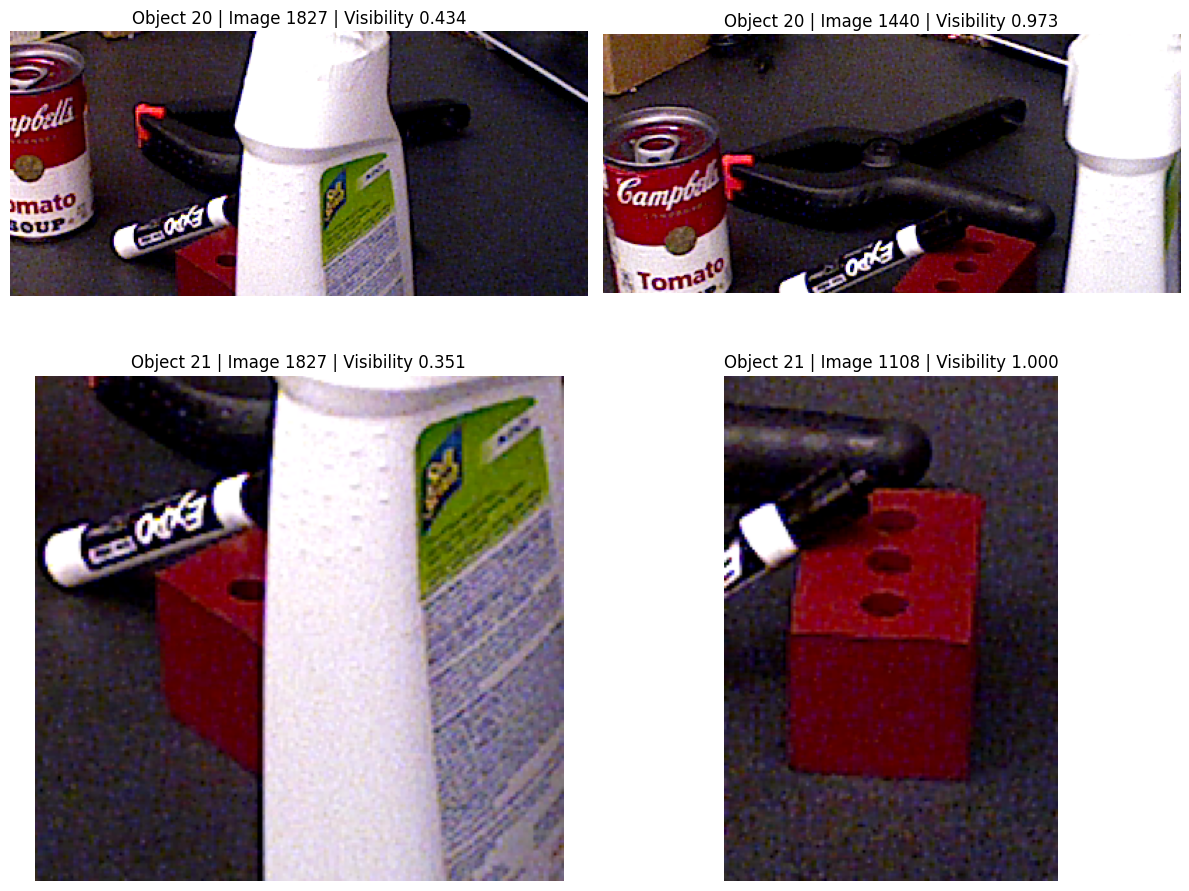

In [26]:
# Load the four real test crops

import os
import json
from PIL import Image
import matplotlib.pyplot as plt

test_scene_path = "/content/ycbv/test/test/000057"

with open(os.path.join(test_scene_path, "scene_gt.json")) as f:
    test_gt = json.load(f)

with open(os.path.join(test_scene_path, "scene_gt_info.json")) as f:
    test_info = json.load(f)


# The four observations we want to test.
test_cases = [
    {"image_id": "1827", "obj_id": 20},
    {"image_id": "1440", "obj_id": 20},
    {"image_id": "1827", "obj_id": 21},
    {"image_id": "1108", "obj_id": 21}
]


test_records = []

for case in test_cases:

    image_id = case["image_id"]
    obj_id = case["obj_id"]

    annotations = test_gt[image_id]
    info_records = test_info[image_id]

    # Find the annotation corresponding to the requested object.
    matching_indices = [
        i for i, annotation in enumerate(annotations)
        if annotation["obj_id"] == obj_id
    ]

    if len(matching_indices) != 1:
        raise ValueError(
            f"Expected one instance of object {obj_id} "
            f"in image {image_id}, found {len(matching_indices)}"
        )

    idx = matching_indices[0]
    info = info_records[idx]

    record = {
        "image_id": image_id,
        "obj_id": obj_id,
        "visibility": info["visib_fract"],
        "bbox_obj": info["bbox_obj"],
        "image_path": os.path.join(
            test_scene_path,
            "rgb",
            f"{int(image_id):06d}.png"
        )
    }

    test_records.append(record)


# Extract crops using the same function and margin as training.
test_crops = [
    extract_crop(record, margin=0.35)
    for record in test_records
]


# Display the four crops.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, record, crop in zip(
    axes.flat, test_records, test_crops
):

    ax.imshow(crop)
    ax.set_title(
        f"Object {record['obj_id']} | "
        f"Image {record['image_id']} | "
        f"Visibility {record['visibility']:.3f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [27]:
# Run Dino and classifier

# Apply the same preprocessing used during training.
test_tensors = []

for crop in test_crops:

    _, tensor = preprocess_dinov2(crop)

    test_tensors.append(tensor)


# Create a batch.
test_batch = torch.stack(test_tensors).to(device)

# Extract DINOv2 features.
model.eval()

with torch.inference_mode():

    test_features = model.forward_features(
        test_batch
    )["x_norm_clstoken"].cpu().numpy()


print("Test feature shape:", test_features.shape)


# Predict using the trained classifier.
test_predictions = classifier.predict(test_features)

# Get class probabilities.
test_probabilities = classifier.predict_proba(test_features)


# Object ID to object name.
object_names = {
    1: "Master Chef Can",
    2: "Cracker Box",
    3: "Sugar Box",
    4: "Tomato Soup Can",
    5: "Mustard Bottle",
    6: "Tuna Fish Can",
    7: "Pudding Box",
    8: "Gelatin Box",
    9: "Potted Meat Can",
    10: "Banana",
    11: "Pitcher Base",
    12: "Bleach Cleanser",
    13: "Bowl",
    14: "Mug",
    15: "Power Drill",
    16: "Wood Block",
    17: "Scissors",
    18: "Large Marker",
    19: "Large Clamp",
    20: "Extra Large Clamp",
    21: "Foam Brick"
}


results = []

for i, record in enumerate(test_records):

    predicted_obj_id = int(test_predictions[i]) + 1

    probabilities = test_probabilities[i]

    top_indices = np.argsort(probabilities)[::-1][:3]

    top_3 = [
        (
            object_names[int(classifier.classes_[j]) + 1],
            float(probabilities[j])
        )
        for j in top_indices
    ]

    results.append({
        "True object": object_names[record["obj_id"]],
        "Image ID": record["image_id"],
        "Visibility": record["visibility"],
        "Predicted object": object_names[predicted_obj_id],
        "Correct": predicted_obj_id == record["obj_id"],
        "Top probability": probabilities.max(),
        "Top 3 predictions": top_3
    })


results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

Test feature shape: (4, 384)
      True object Image ID  Visibility Predicted object  Correct  Top probability                                                                                                      Top 3 predictions
Extra Large Clamp     1827    0.434476     Large Marker    False         0.354562    [(Large Marker, 0.35456203822280796), (Bleach Cleanser, 0.2964211831378258), (Tomato Soup Can, 0.2948398615676678)]
Extra Large Clamp     1440    0.972502      Large Clamp    False         0.595291             [(Large Clamp, 0.595291010848124), (Tomato Soup Can, 0.3197306316972036), (Scissors, 0.05135518373411254)]
       Foam Brick     1827    0.351283     Large Marker    False         0.963198 [(Large Marker, 0.9631981348780918), (Tomato Soup Can, 0.023003267856997203), (Potted Meat Can, 0.012999714533045152)]
       Foam Brick     1108    0.999519     Large Marker    False         0.992907      [(Large Marker, 0.9929073399043188), (Foam Brick, 0.006906783869471526), (Tuna F